# Demo 2 Logistic Regression and Multiclass Classification

Lecture slide 26. Explore scores, probabilities, losses, learning, and class decisions.

**How to use in Google Colab**
1. Upload this `.ipynb` using **File → Upload notebook**.
2. Select **Runtime → Run all**. A CPU runtime is sufficient.
3. Read the default figures, then move the sliders. Release a slider to redraw.

All figures and controls use English. All datasets are generated locally with fixed random seeds.
Changing a control never requires uploading a file. If a widget is unavailable, edit the
arguments of the corresponding `..._view(...)` call and rerun that cell.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.special import expit
from IPython.display import display
import ipywidgets as widgets
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass  # Also runs in a standard Jupyter environment.

BLUE, ORANGE, TEAL, NAVY = '#1479e8', '#ff8a20', '#079f9f', '#10264e'
COLORS = [BLUE, ORANGE, TEAL]
REGIONS = ListedColormap(['#dfedff', '#ffe8d5', '#d7f3ef'])
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.labelcolor':NAVY,
                     'axes.titlesize':12, 'figure.constrained_layout.use':True})

def slider(value, low, high, step, label):
    return widgets.FloatSlider(value=value, min=low, max=high, step=step,
                               description=label, continuous_update=False,
                               style={'description_width':'initial'})

def integer(value, low, high, label, step=1):
    return widgets.IntSlider(value=value, min=low, max=high, step=step,
                             description=label, continuous_update=False,
                             style={'description_width':'initial'})

def controls(fn, **kwargs):
    # Release the slider to redraw. A normal static example is shown above each control.
    panel = widgets.interactive(fn, **kwargs)
    display(panel)
    return panel

def class_points(ax, X, y, alpha=1, size=26):
    for k in np.unique(y):
        ax.scatter(*X[y==k].T, c=COLORS[int(k)], s=size, alpha=alpha,
                   edgecolors='white', linewidths=.4, label=['P','Q','R'][int(k)])

def mesh(X, n=150, pad=.7):
    lo, hi = X.min(axis=0)-pad, X.max(axis=0)+pad
    gx, gy = np.meshgrid(np.linspace(lo[0],hi[0],n), np.linspace(lo[1],hi[1],n))
    return gx, gy, np.c_[gx.ravel(),gy.ravel()]

print('Ready. CPU is sufficient. No external datasets are required.')

Ready. CPU is sufficient. No external datasets are required.


## 1 From a linear score to a probability
Both $x_1$ and $x_2$ are **input features**. The output is a class.
We use $s=c(\cos\alpha\,x_1+\sin\alpha\,x_2+b)$ and $p=\sigma(s)=1/(1+e^{-s})$.
P has target $t=1$ (blue); Q has target $t=0$ (orange).

The **boundary at p=0.5** is a line. Changing confidence $c>0$ keeps this boundary fixed,
but changes the probabilities and the cross-entropy. A different decision threshold changes
the final class decisions without changing the learned probability model.

Error rate: 0.079   Mean cross-entropy: 0.319


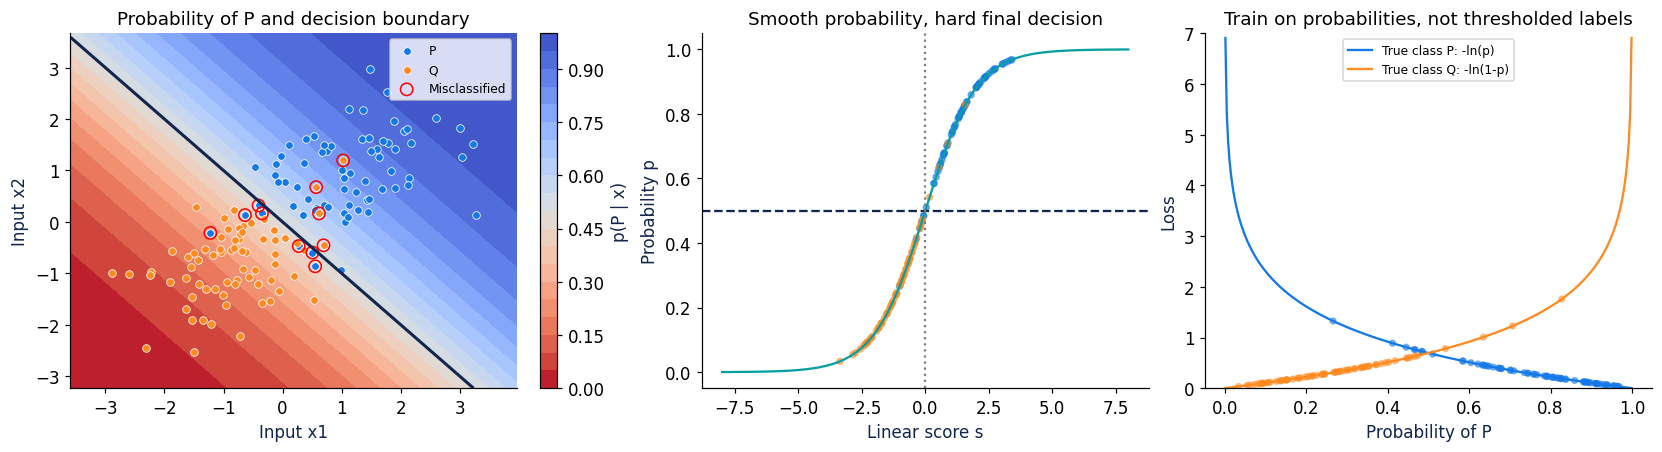

In [5]:
rng_binary=np.random.default_rng(21)
X_binary=np.r_[rng_binary.multivariate_normal([1.0,.8],[[.8,.3],[.3,.8]],70),
                rng_binary.multivariate_normal([-1.,-.8],[[.8,.3],[.3,.8]],70)]
t_binary=np.r_[np.ones(70),np.zeros(70)]

def binary_loss(beta):
    D=np.c_[X_binary,np.ones(len(X_binary))];s=D@beta
    return np.mean(np.logaddexp(0,s)-t_binary*s)

def classification_view(angle=45., bias=0., confidence=1., threshold=.5):
    rad=np.deg2rad(angle);beta=confidence*np.array([np.cos(rad),np.sin(rad),bias])
    scores=np.c_[X_binary,np.ones(len(X_binary))]@beta;p=expit(scores)
    pred=p>=threshold;wrong=pred!=t_binary.astype(bool)
    gx,gy,G=mesh(X_binary)
    pg=expit(np.c_[G,np.ones(len(G))]@beta).reshape(gx.shape)
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    cf=axs[0].contourf(gx,gy,pg,levels=np.linspace(0,1,21),cmap='coolwarm_r',vmin=0,vmax=1)
    if pg.min()<threshold<pg.max():axs[0].contour(gx,gy,pg,levels=[threshold],colors=NAVY,linewidths=2)
    if threshold!=.5:axs[0].contour(gx,gy,pg,levels=[.5],colors='gray',linestyles='--')
    for label,color,name in [(1,BLUE,'P'),(0,ORANGE,'Q')]:
        axs[0].scatter(*X_binary[t_binary==label].T,c=color,s=25,edgecolors='white',linewidths=.5,label=name)
    axs[0].scatter(*X_binary[wrong].T,facecolors='none',edgecolors='red',s=65,label='Misclassified')
    axs[0].set(xlabel='Input x1',ylabel='Input x2',title='Probability of P and decision boundary')
    axs[0].legend(fontsize=8);fig.colorbar(cf,ax=axs[0],label='p(P | x)')
    ss=np.linspace(-8,8,300)
    axs[1].plot(ss,expit(ss),c=TEAL)
    axs[1].scatter(scores,p,c=np.where(t_binary==1,BLUE,ORANGE),s=15,alpha=.55)
    axs[1].axhline(threshold,c=NAVY,ls='--');axs[1].axvline(0,c='gray',ls=':')
    axs[1].set(xlabel='Linear score s',ylabel='Probability p',title='Smooth probability, hard final decision')
    pp=np.linspace(.001,.999,300)
    axs[2].plot(pp,-np.log(pp),c=BLUE,label='True class P: -ln(p)')
    axs[2].plot(pp,-np.log1p(-pp),c=ORANGE,label='True class Q: -ln(1-p)')
    sample_losses=np.logaddexp(0,scores)-t_binary*scores
    axs[2].scatter(p,sample_losses,c=np.where(t_binary==1,BLUE,ORANGE),s=14,alpha=.5)
    axs[2].set(xlabel='Probability of P',ylabel='Loss',ylim=(0,7),title='Train on probabilities, not thresholded labels')
    axs[2].legend(fontsize=8);plt.show()
    print(f'Error rate: {wrong.mean():.3f}   Mean cross-entropy: {sample_losses.mean():.3f}')

classification_view()

Error rate: 0.079   Mean cross-entropy: 0.319


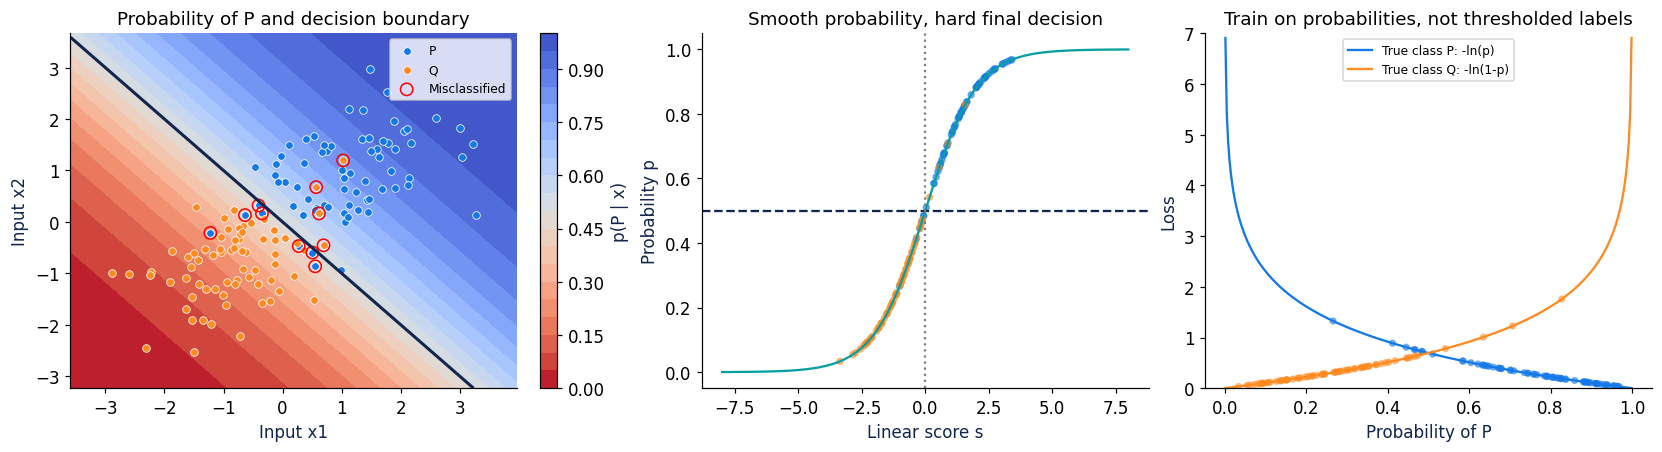

interactive(children=(FloatSlider(value=45.0, continuous_update=False, description='Boundary normal angle', ma…

In [6]:
binary_controls=controls(classification_view,
    angle=slider(45,-180,180,5,'Boundary normal angle'),bias=slider(0,-2,2,.1,'Bias'),
    confidence=slider(1,.2,6,.2,'Confidence scale'),threshold=slider(.5,.1,.9,.05,'Decision threshold'))

## 2 Train the classifier using gradients
Let $D=[x_1,x_2,1]$, so the final parameter is the intercept.
For the mean binary cross-entropy,
$\nabla_\beta L=D^T(p-t)/N$.

The optimization below uses the smooth loss **before** class thresholding.
Move the update slider to inspect intermediate models. Classification error is measured
at threshold 0.5; it need not decrease at every update even when cross-entropy decreases.

beta = [ 0.694  1.88  -0.231]; cross-entropy = 0.2428; error = 0.0714


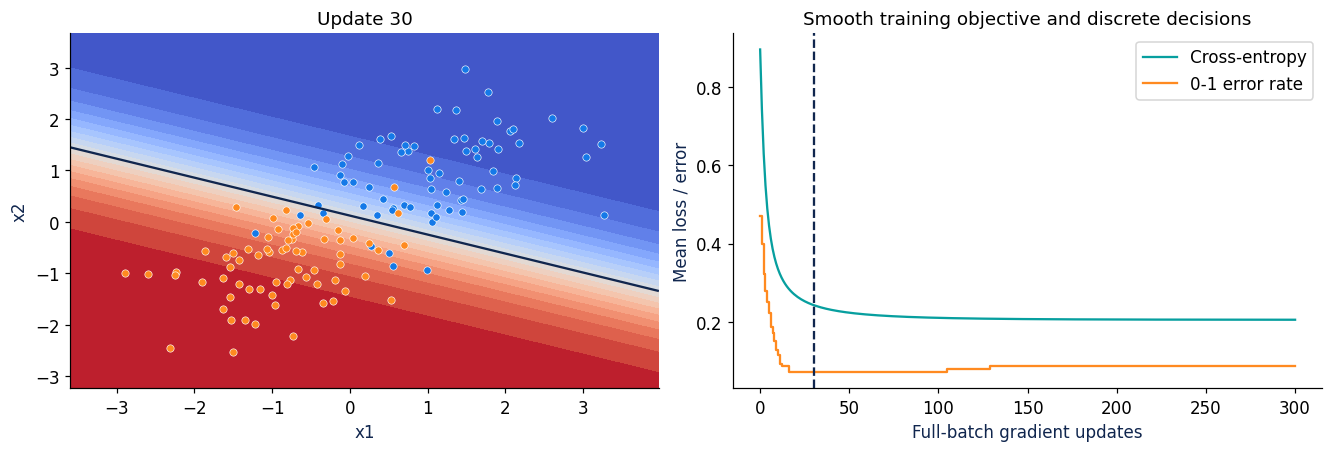

In [8]:
from functools import lru_cache
D_binary=np.c_[X_binary,np.ones(len(X_binary))]

@lru_cache(maxsize=20)
def train_binary(eta):
    beta=np.array([-1.,1.,-.7]);history=[beta.copy()]
    for step in range(300):
        p=expit(D_binary@beta)
        beta=beta-eta*(D_binary.T@(p-t_binary)/len(t_binary))
        history.append(beta.copy())
    return np.array(history)

def training_view(update=30, eta=.3):
    hist=train_binary(eta);beta=hist[update]
    gx,gy,G=mesh(X_binary);pg=expit(np.c_[G,np.ones(len(G))]@beta).reshape(gx.shape)
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    axs[0].contourf(gx,gy,pg,levels=np.linspace(0,1,21),cmap='coolwarm_r')
    if pg.min()<.5<pg.max():axs[0].contour(gx,gy,pg,levels=[.5],colors=NAVY)
    for label,c in [(1,BLUE),(0,ORANGE)]:axs[0].scatter(*X_binary[t_binary==label].T,c=c,edgecolors='white',s=23,linewidths=.4)
    axs[0].set(xlabel='x1',ylabel='x2',title=f'Update {update}')
    all_scores=D_binary@hist.T
    ce=np.mean(np.logaddexp(0,all_scores)-t_binary[:,None]*all_scores,axis=0)
    err=np.mean((all_scores>=0)!=t_binary[:,None],axis=0)
    axs[1].plot(ce,c=TEAL,label='Cross-entropy')
    axs[1].step(np.arange(len(err)),err,c=ORANGE,label='0-1 error rate',where='post')
    axs[1].axvline(update,c=NAVY,ls='--')
    axs[1].set(xlabel='Full-batch gradient updates',ylabel='Mean loss / error',title='Smooth training objective and discrete decisions')
    axs[1].legend();plt.show()
    print(f'beta = {np.round(beta,3)}; cross-entropy = {ce[update]:.4f}; error = {err[update]:.4f}')

training_view()

beta = [ 0.694  1.88  -0.231]; cross-entropy = 0.2428; error = 0.0714


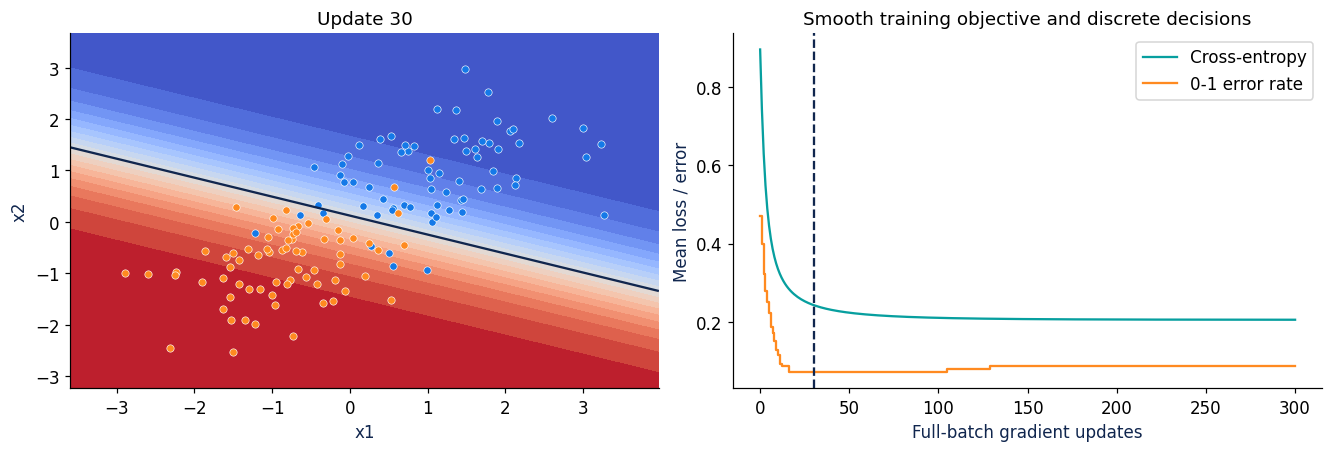

interactive(children=(IntSlider(value=30, continuous_update=False, description='Update', max=300, style=Slider…

In [9]:
training_controls=controls(training_view,update=integer(30,0,300,'Update'),eta=slider(.3,.02,1,.02,'Learning rate'))

## 3 Three routes to multiclass classification
P, Q, and R are now three output classes, while the input still has **two features**.

- **One-vs-Rest:** three binary logistic models; choose the largest positive-class probability.
  These independently fitted probabilities need not sum to one.
- **One-vs-One:** three pairwise logistic models; use majority voting. For a tie, this demo
  uses the summed pairwise support, then class order for an exact remaining tie.
- **Softmax:** learn all class scores jointly with multiclass cross-entropy;
  the class probabilities sum to one.

The same training split is used by all three methods. Move the query point and compare
scores, votes, probabilities, and decision regions. The validation split is not used to fit parameters.

Class order: P, Q, R
OvR positive-class probabilities: [0.03  0.01  0.139] (not normalized)
OvO votes: [0 1 2] ; pair winners (P/Q, P/R, Q/R): ['Q', 'R', 'R']
Softmax probabilities: [0.178 0.04  0.782]


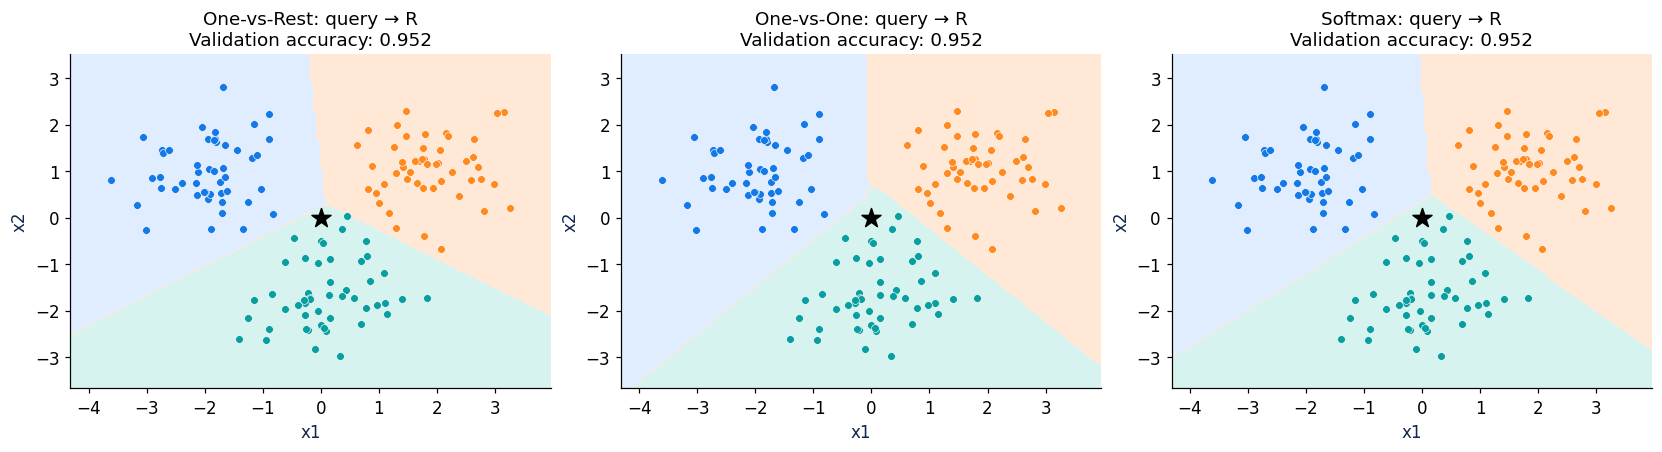

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

rng_multi=np.random.default_rng(7)
X_multi=np.r_[rng_multi.normal([-1.8,1.2],.72,(70,2)),
              rng_multi.normal([1.8,1.2],.72,(70,2)),rng_multi.normal([0,-1.6],.72,(70,2))]
y_multi=np.repeat(np.arange(3),70)
Xm, Xmv, ym, ymv=train_test_split(X_multi,y_multi,test_size=.3,stratify=y_multi,random_state=3)
ovr_models=[LogisticRegression(C=10,max_iter=1000).fit(Xm,(ym==k).astype(int)) for k in range(3)]
pairs=[(0,1),(0,2),(1,2)];ovo_models=[]
for i,j in pairs:
    keep=(ym==i)|(ym==j)
    ovo_models.append(LogisticRegression(C=10,max_iter=1000).fit(Xm[keep],ym[keep]))
softmax_model=LogisticRegression(C=10,max_iter=1000,solver='lbfgs').fit(Xm,ym)

def ovr_scores(X):return np.column_stack([m.predict_proba(X)[:,1] for m in ovr_models])

def ovo_details(X):
    votes=np.zeros((len(X),3),dtype=int);support=np.zeros((len(X),3));individual=[]
    for (i,j),model in zip(pairs,ovo_models):
        pp=model.predict_proba(X);winner=model.classes_[np.argmax(pp,axis=1)]
        votes[np.arange(len(X)),winner]+=1;individual.append(winner)
        support[:,i]+=pp[:,0];support[:,j]+=pp[:,1]
    eligible=votes==votes.max(axis=1,keepdims=True)
    pred=np.argmax(np.where(eligible,support,-np.inf),axis=1)
    return pred,votes,support,np.array(individual).T

def multiclass_view(query_x1=0.,query_x2=0.):
    query=np.array([[query_x1,query_x2]]);gx,gy,G=mesh(X_multi)
    regions=[ovr_scores(G).argmax(axis=1),ovo_details(G)[0],softmax_model.predict(G)]
    qpred=[ovr_scores(query).argmax(axis=1)[0],ovo_details(query)[0][0],softmax_model.predict(query)[0]]
    vpred=[ovr_scores(Xmv).argmax(axis=1),ovo_details(Xmv)[0],softmax_model.predict(Xmv)]
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    for ax,title,r,k,v in zip(axs,['One-vs-Rest','One-vs-One','Softmax'],regions,qpred,vpred):
        ax.contourf(gx,gy,r.reshape(gx.shape),levels=[-.5,.5,1.5,2.5],cmap=REGIONS)
        class_points(ax,Xm,ym)
        ax.scatter(*query.T,c='black',marker='*',s=170,zorder=5)
        ax.set(xlabel='x1',ylabel='x2',title=f'{title}: query → {"PQR"[k]}\nValidation accuracy: {np.mean(v==ymv):.3f}')
    plt.show()
    pr,votes,support,individual=ovo_details(query)
    print('Class order: P, Q, R')
    print('OvR positive-class probabilities:',np.round(ovr_scores(query)[0],3), '(not normalized)')
    print('OvO votes:',votes[0],'; pair winners (P/Q, P/R, Q/R):',["PQR"[k] for k in individual[0]])
    print('Softmax probabilities:',np.round(softmax_model.predict_proba(query)[0],3))

multiclass_view()

Class order: P, Q, R
OvR positive-class probabilities: [0.03  0.01  0.139] (not normalized)
OvO votes: [0 1 2] ; pair winners (P/Q, P/R, Q/R): ['Q', 'R', 'R']
Softmax probabilities: [0.178 0.04  0.782]


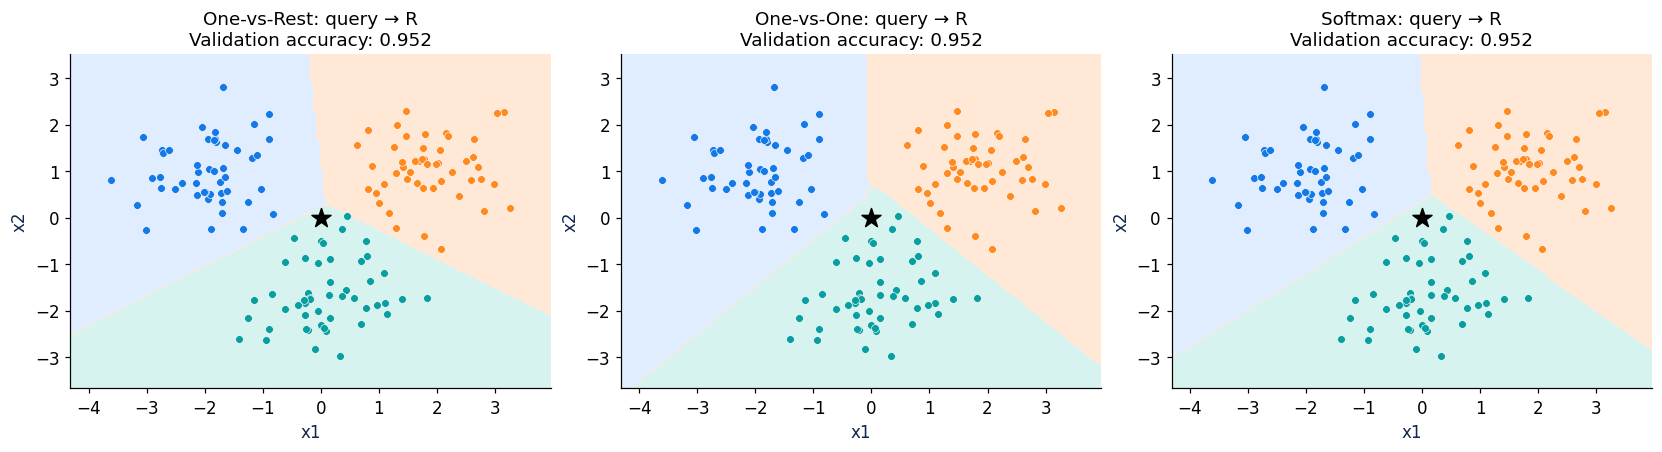

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='Query x1', max=4.0, min=-4.…

In [12]:
multiclass_controls=controls(multiclass_view,
    query_x1=slider(0,-4,4,.1,'Query x1'),query_x2=slider(0,-4,4,.1,'Query x2'))

## Check your understanding
1. Can the classification error stay fixed while cross-entropy changes?
2. Does changing the prediction threshold require retraining?
3. How many binary classifiers do OvR and OvO require for K classes?
4. Why should OvR outputs not be interpreted as a normalized multiclass distribution?

**Documentation:** [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
[multiclass strategies](https://scikit-learn.org/stable/modules/multiclass.html).